In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import seaborn as sns

a)

In [3]:
stock_files = ["stocks/aapl.csv", "stocks/goog.csv", "stocks/msft.csv", "stocks/bac.csv", "stocks/c.csv", "stocks/wfc.csv", "stocks/f.csv", "stocks/tym.csv", "stocks/hmc.csv"]

# Read stock data
stock_data = {}
for file in stock_files:
    stock_name = file.split(".")[0]
    df = pd.read_csv(file, parse_dates=["Date"], index_col="Date")  # Parse date column and sort by date
    df = df.sort_index()
    stock_data[stock_name] = df

In [4]:
stock_data['stocks/aapl']

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2007-01-03,86.289999,86.579999,81.899999,83.800002,309579900,10.904162
2007-01-04,84.050001,85.949998,83.820003,85.659998,211815100,11.146187
2007-01-05,85.770000,86.199997,84.400002,85.049997,208685400,11.066813
2007-01-08,85.959998,86.529998,85.280003,85.470000,199276700,11.121465
2007-01-09,86.450003,92.979999,85.150000,92.570003,837324600,12.045326
...,...,...,...,...,...,...
2016-12-23,115.589996,116.519997,115.589996,116.519997,14181200,116.519997
2016-12-27,116.519997,117.800003,116.489998,117.260002,18071900,117.260002
2016-12-28,117.519997,118.019997,116.199997,116.760002,20582000,116.760002


b)

In [6]:
stock_changes = {}
for stock, df in stock_data.items():
    df["Change"] = df["Close"].diff()  # Compute price difference
    stock_changes[stock] = df["Change"]

In [7]:
stock_changes['stocks/aapl']

Date
2007-01-03         NaN
2007-01-04    1.859996
2007-01-05   -0.610001
2007-01-08    0.420003
2007-01-09    7.100003
                ...   
2016-12-23    0.229996
2016-12-27    0.740005
2016-12-28   -0.500000
2016-12-29   -0.029999
2016-12-30   -0.910003
Name: Change, Length: 2518, dtype: float64

c)

In [9]:
stocks_df = pd.DataFrame(stock_changes)
stocks_df.dropna(inplace=True)  # Drop first row
stocks_df.head()

,stocks/aapl,stocks/goog,stocks/msft,stocks/bac,stocks/c,stocks/wfc,stocks/f,stocks/tym,stocks/hmc
Date,,,,,,,,,
2007-01-04,1.859996,15.670023,-0.050002,0.339996,-0.190003,0.059997,0.19,2.470001,0.330002
2007-01-05,-0.610001,3.929996,-0.170000,-0.429996,-0.289996,-0.200001,-0.08,-4.050003,-1.370003
2007-01-08,0.420003,-3.609983,0.290001,0.209999,0.279999,-0.099998,0.11,0.250000,0.220001
2007-01-09,7.100003,1.919984,0.029999,0.049999,-0.479999,0.090000,0.06,-1.809997,0.020001
2007-01-10,4.429994,3.960015,-0.299999,0.080002,-0.440002,-0.110000,-0.06,-2.730011,-0.970001


d)

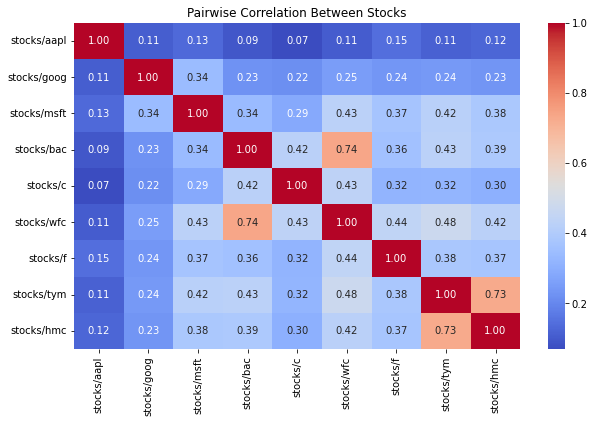

In [11]:
correlation_matrix = stocks_df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pairwise Correlation Between Stocks")
plt.show()

e)

In [13]:
finance_stocks = ["stocks/bac", "stocks/c", "stocks/wfc"]
tech_stocks = ["stocks/aapl", "stocks/goog", "stocks/msft"]

# Within-group correlation for Finance and Banking
finance_corr_values = []
for i in range(len(finance_stocks)):
    for j in range(i + 1, len(finance_stocks)):
        finance_corr_values.append(correlation_matrix.loc[finance_stocks[i], finance_stocks[j]])

avg_finance_corr = np.mean(finance_corr_values)

# Between-group correlation (Finance vs Tech)
between_corr_values = []
for finance in finance_stocks:
    for tech in tech_stocks:
        between_corr_values.append(correlation_matrix.loc[finance, tech])

avg_between_corr = np.mean(between_corr_values)

print(f"Average Correlation (Within Finance Stocks): {avg_finance_corr:.2f}")
print(f"Average Correlation (Between Finance vs Tech Stocks): {avg_between_corr:.2f}")


Average Correlation (Within Finance Stocks): 0.53
Average Correlation (Between Finance vs Tech Stocks): 0.22


f)

In [15]:
pca = PCA(n_components=3)
pca_result = pca.fit_transform(stocks_df.fillna(0))  # Fill NaNs with 0
components = pca.components_

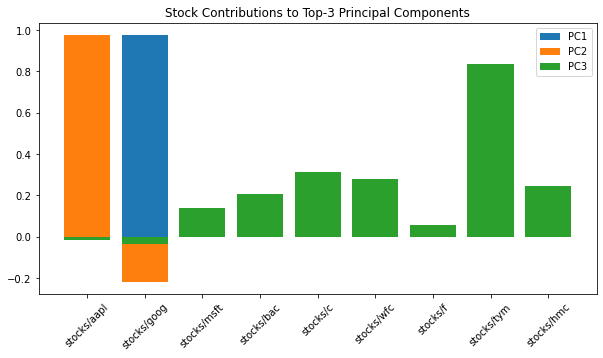

Explained Variance Ratios: [0.61457723 0.37272875 0.00744914]


In [16]:
# Plot
plt.figure(figsize=(10, 5))
x_labels = stocks_df.columns
for i in range(3):
    plt.bar(x_labels, components[i], label=f"PC{i+1}")

plt.legend()
plt.title("Stock Contributions to Top-3 Principal Components")
plt.xticks(rotation=45)
plt.show()

print("Explained Variance Ratios:", pca.explained_variance_ratio_)